In [2]:
from pathlib import Path
from collections import Counter

# Dataset A location
dataset_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\Road Damage Annotated Data\Data Y12 Final"
)

# Class mapping from data.yaml
class_names = {
    0: "Crack",
    1: "Pothole",
    2: "Surface Erosion"
}

# Count annotations
counts = Counter()

for label_file in dataset_path.rglob("labels/*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            line = line.strip()

            if line:
                class_id = int(line.split()[0])
                counts[class_names[class_id]] += 1

print("Annotation counts:")
for class_name, count in counts.items():
    print(f"{class_name}: {count}")

Annotation counts:
Crack: 522
Surface Erosion: 397
Pothole: 927


In [3]:
from pathlib import Path
import zipfile

# Short paths to avoid Windows path-length problems
zip_folder = Path(r"C:\RH")
extract_folder = Path(r"C:\RH\civic")

# Find the ZIP automatically
zip_files = list(zip_folder.glob("*.zip"))

print("ZIP files found:")
for z in zip_files:
    print(z)

if not zip_files:
    print("❌ No ZIP file found in C:\\RH")
else:
    zip_path = zip_files[0]

    print(f"\nExtracting: {zip_path.name}")
    print("Please wait...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_folder)

    print("\n✅ Extraction completed!")
    print("Extracted to:", extract_folder)
    

ZIP files found:
❌ No ZIP file found in C:\RH


In [4]:
from pathlib import Path

downloads = Path(r"C:\Users\tript\Downloads")

zip_files = list(downloads.rglob("*.zip"))

print("ZIP files found in Downloads:\n")

for z in zip_files:
    print(z)

ZIP files found in Downloads:

C:\Users\tript\Downloads\Agro-AI-main.zip
C:\Users\tript\Downloads\ai-agent-security-multi-step-tool-attacks.zip
C:\Users\tript\Downloads\Civic-issue-detection.v1-civic-detector.yolov8.zip
C:\Users\tript\Downloads\daa-zip (3) (1).zip
C:\Users\tript\Downloads\daa-zip (3) (2).zip
C:\Users\tript\Downloads\daa-zip (3).zip
C:\Users\tript\Downloads\files.zip
C:\Users\tript\Downloads\FINAL RESUME.zip
C:\Users\tript\Downloads\Indian-Road-Damage-Infrastructure-Dataset-main.zip
C:\Users\tript\Downloads\mcp-learning-path-demo-main.zip
C:\Users\tript\Downloads\Minor Project 1 June.zip
C:\Users\tript\Downloads\mysql-connector-j-9.6.0.zip
C:\Users\tript\Downloads\Road Damage Annotated Data.zip
C:\Users\tript\Downloads\Session 2 Homework Assignment (1).zip
C:\Users\tript\Downloads\Session 2 Homework Assignment.zip
C:\Users\tript\Downloads\RH\Civic-issue-detection.v1-civic-detector.yolov8.zip
C:\Users\tript\Downloads\yt notes coding\SQL (OneShot)-20260711T121310Z-2-001.z

## 3.3 Add Waterlogging and Debris Data

To extend the road-damage dataset with additional real-world hazards, a Civic Issue Detection dataset is used.

Only the required classes are retained:

- **Garbage → Debris**
- **Waterlogging → Waterlogging**
- **Road Damage → Ignored**

The original class IDs are remapped to the final four-class scheme:

| Original Class | Final Class |
|---|---|
| Garbage | Debris (3) |
| Road Damage | Ignored |
| Waterlogging | Waterlogging (2) |

The original dataset remains unchanged; only the required images and YOLO annotations are copied into the final dataset.

In [5]:
from pathlib import Path
import zipfile

zip_path = Path(
    r"C:\Users\tript\Downloads\RH\Civic-issue-detection.v1-civic-detector.yolov8.zip"
)

extract_path = Path(r"C:\RH\civic")

extract_path.mkdir(parents=True, exist_ok=True)

print("ZIP:", zip_path)
print("Extracting to:", extract_path)
print("Please wait...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\n✅ Extraction completed!")
print("Location:", extract_path)

ZIP: C:\Users\tript\Downloads\RH\Civic-issue-detection.v1-civic-detector.yolov8.zip
Extracting to: C:\RH\civic
Please wait...

✅ Extraction completed!
Location: C:\RH\civic


In [6]:
from pathlib import Path

civic_path = Path(r"C:\RH\civic")

print("Dataset contents:\n")

for item in civic_path.iterdir():
    print(item.name)

Dataset contents:

data.yaml
README.dataset.txt
README.roboflow.txt
test
train
valid


In [7]:
from pathlib import Path

yaml_path = Path(r"C:\RH\civic\data.yaml")

print(yaml_path.read_text())


train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['garbage', 'road_damage', 'waterlogging']

roboflow:
  workspace: chintan-sood
  project: civic-issue-detection-q5kr9
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/chintan-sood/civic-issue-detection-q5kr9/dataset/1


In [8]:
from pathlib import Path
from collections import Counter

civic_path = Path(r"C:\RH\civic")

counts = Counter()

for label_file in civic_path.rglob("labels/*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            line = line.strip()
            if line:
                class_id = int(line.split()[0])
                counts[class_id] += 1

print("Civic dataset annotation counts:")

for class_id, count in sorted(counts.items()):
    class_name = {
        0: "garbage → debris",
        1: "road_damage → IGNORE",
        2: "waterlogging → waterlogging"
    }.get(class_id, "UNKNOWN")

    print(f"Class {class_id} ({class_name}): {count}")
    

Civic dataset annotation counts:
Class 0 (garbage → debris): 17517
Class 1 (road_damage → IGNORE): 82042
Class 2 (waterlogging → waterlogging): 3842


In [9]:
from pathlib import Path
import shutil

# =========================
# PATHS
# =========================

project = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection"
)

# Existing YOLO road-damage dataset
road_damage = project / "dataset" / "Road Damage Annotated Data" / "Data Y12 Final"

# Civic dataset
civic = Path(r"C:\RH\civic")

# Final dataset
final = project / "dataset" / "road_hazard_final"

# =========================
# CREATE FINAL FOLDERS
# =========================

for split in ["train", "val", "test"]:
    (final / split / "images").mkdir(parents=True, exist_ok=True)
    (final / split / "labels").mkdir(parents=True, exist_ok=True)

print("✅ Final dataset folders ready:")
print(final)

✅ Final dataset folders ready:
C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final


In [10]:
from pathlib import Path
import shutil

# Existing Road Damage YOLO dataset
road_damage = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\Road Damage Annotated Data\Data Y12 Final"
)

# Final dataset
final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

# Original classes:
# 0 = Crack
# 1 = Pothole
# 2 = Surface Erosion (ignore)
#
# Final classes:
# 0 = Pothole
# 1 = Crack

class_mapping = {
    0: 1,  # Crack -> Crack
    1: 0,  # Pothole -> Pothole
}

copied = 0
skipped = 0

for source_split, final_split in [
    ("train", "train"),
    ("valid", "val"),
]:
    image_dir = road_damage / source_split / "images"
    label_dir = road_damage / source_split / "labels"

    for label_file in label_dir.glob("*.txt"):

        # Read annotations
        new_lines = []

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                old_class = int(parts[0])

                # Ignore Surface Erosion
                if old_class not in class_mapping:
                    continue

                parts[0] = str(class_mapping[old_class])
                new_lines.append(" ".join(parts))

        # Skip images that contain only Surface Erosion
        if not new_lines:
            skipped += 1
            continue

        # Find corresponding image
        image_found = None

        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
            candidate = image_dir / (label_file.stem + ext)
            if candidate.exists():
                image_found = candidate
                break

        if image_found is None:
            continue

        # Make unique filename
        new_name = f"road_{source_split}_{label_file.stem}"

        destination_image = (
            final / final_split / "images" / f"{new_name}{image_found.suffix}"
        )

        destination_label = (
            final / final_split / "labels" / f"{new_name}.txt"
        )

        shutil.copy2(image_found, destination_image)

        with open(destination_label, "w") as f:
            f.write("\n".join(new_lines) + "\n")

        copied += 1

print("✅ Pothole + Crack added!")
print("Images copied:", copied)
print("Images skipped:", skipped)

✅ Pothole + Crack added!
Images copied: 754
Images skipped: 321


In [11]:
from pathlib import Path
import shutil

# Civic dataset
civic = Path(r"C:\RH\civic")

# Final dataset
final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

# Civic classes → Final classes
# 0 garbage      → 3 debris
# 1 road_damage  → ignore
# 2 waterlogging → 2 waterlogging

class_mapping = {
    0: 3,
    2: 2
}

copied = 0
skipped = 0

for source_split, final_split in [
    ("train", "train"),
    ("valid", "val"),
    ("test", "test")
]:
    image_dir = civic / source_split / "images"
    label_dir = civic / source_split / "labels"

    for label_file in label_dir.glob("*.txt"):

        new_lines = []

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                old_class = int(parts[0])

                # Keep only garbage and waterlogging
                if old_class not in class_mapping:
                    continue

                parts[0] = str(class_mapping[old_class])
                new_lines.append(" ".join(parts))

        # Skip images containing only road_damage
        if not new_lines:
            skipped += 1
            continue

        # Find corresponding image
        image_found = None

        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
            candidate = image_dir / (label_file.stem + ext)

            if candidate.exists():
                image_found = candidate
                break

        if image_found is None:
            continue

        # Unique filename
        new_name = f"civic_{source_split}_{label_file.stem}"

        destination_image = (
            final / final_split / "images" /
            f"{new_name}{image_found.suffix}"
        )

        destination_label = (
            final / final_split / "labels" /
            f"{new_name}.txt"
        )

        shutil.copy2(image_found, destination_image)

        with open(destination_label, "w") as f:
            f.write("\n".join(new_lines) + "\n")

        copied += 1

print("✅ Waterlogging + Debris added!")
print("Images copied:", copied)
print("Images skipped:", skipped)

✅ Waterlogging + Debris added!
Images copied: 7835
Images skipped: 36260


### Final Hazard Classes

The combined dataset uses four target classes:

| ID | Hazard |
|---:|---|
| 0 | Pothole |
| 1 | Crack |
| 2 | Waterlogging |
| 3 | Debris |

This unified class mapping ensures that all source datasets follow the same label format before YOLO training.

In [12]:
from pathlib import Path
import shutil

# =========================
# PATHS
# =========================

civic = Path(r"C:\RH\civic")

final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

# Civic → Final class mapping
# 0 garbage      → 3 debris
# 1 road_damage  → ignore
# 2 waterlogging → 2 waterlogging

class_mapping = {
    0: 3,
    2: 2
}

copied = 0
skipped = 0

# =========================
# PROCESS DATASET
# =========================

for source_split, final_split in [
    ("train", "train"),
    ("valid", "val"),
    ("test", "test")
]:

    image_dir = civic / source_split / "images"
    label_dir = civic / source_split / "labels"

    # Index images once instead of searching repeatedly
    image_map = {}

    for image in image_dir.iterdir():
        if image.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_map[image.stem] = image

    print(f"\nProcessing {source_split}...")

    for label_file in label_dir.glob("*.txt"):

        new_lines = []

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                old_class = int(parts[0])

                # Keep only garbage and waterlogging
                if old_class not in class_mapping:
                    continue

                # Remap class
                parts[0] = str(class_mapping[old_class])

                new_lines.append(" ".join(parts))

        # Skip images containing only road_damage
        if not new_lines:
            skipped += 1
            continue

        # Find image from pre-built index
        image_found = image_map.get(label_file.stem)

        if image_found is None:
            continue

        # Unique filename
        new_name = f"civic_{source_split}_{label_file.stem}"

        destination_image = (
            final / final_split / "images" /
            f"{new_name}{image_found.suffix}"
        )

        destination_label = (
            final / final_split / "labels" /
            f"{new_name}.txt"
        )

        # Copy image
        shutil.copy2(image_found, destination_image)

        # Write remapped labels
        with open(destination_label, "w") as f:
            f.write("\n".join(new_lines) + "\n")

        copied += 1

        # Progress indicator
        if copied % 500 == 0:
            print(f"  Copied {copied} images...")

print("\n" + "=" * 50)
print("✅ Waterlogging + Debris added!")
print("=" * 50)
print("Images copied :", copied)
print("Images skipped:", skipped)


Processing train...
  Copied 500 images...
  Copied 1000 images...
  Copied 1500 images...
  Copied 2000 images...
  Copied 2500 images...
  Copied 3000 images...
  Copied 3500 images...
  Copied 4000 images...
  Copied 4500 images...
  Copied 5000 images...
  Copied 5500 images...
  Copied 6000 images...
  Copied 6500 images...
  Copied 7000 images...

Processing valid...

Processing test...
  Copied 7500 images...

✅ Waterlogging + Debris added!
Images copied : 7835
Images skipped: 36260


## 3.4 Final Dataset Verification

The selected datasets have been combined into a unified YOLO-format dataset.

The final hazard classes are:

| Class ID | Hazard |
|---:|---|
| 0 | Pothole |
| 1 | Crack |
| 2 | Waterlogging |
| 3 | Debris |

Only the required hazard categories are retained. Unwanted classes such as surface erosion and generic road damage are excluded.

In [13]:
from pathlib import Path
from collections import Counter

final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

class_names = {
    0: "Pothole",
    1: "Crack",
    2: "Waterlogging",
    3: "Debris"
}

counts = Counter()

for label_file in final.rglob("labels/*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) == 5:
                class_id = int(parts[0])
                counts[class_id] += 1

print("Final annotation distribution:\n")

for class_id in range(4):
    print(
        f"{class_id} - {class_names[class_id]}: "
        f"{counts[class_id]} bounding boxes"
    )

Final annotation distribution:

0 - Pothole: 927 bounding boxes
1 - Crack: 522 bounding boxes
2 - Waterlogging: 1 bounding boxes
3 - Debris: 17517 bounding boxes


## 3.5 Validate Waterlogging Annotations

The source Civic dataset contains waterlogging annotations that must be preserved during dataset integration.

A validation step is performed to ensure that waterlogging bounding boxes were correctly remapped to the final class ID `2`.

In [17]:
from pathlib import Path

civic = Path(r"C:\RH\civic")

found = 0
examples = []

for label_file in (civic / "train" / "labels").glob("*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) == 5 and parts[0] == "2":
                found += 1

                if len(examples) < 5:
                    examples.append((label_file.name, line.strip()))

print("Waterlogging boxes found in Civic TRAIN:", found)

print("\nFirst few examples:")
for name, line in examples:
    print(name, "->", line)

Waterlogging boxes found in Civic TRAIN: 1

First few examples:
OIP-ZfzXNTcKMag8fBZ3bEjLHQHaDt_jpg.rf.79c6070409c0675782166bc7f6bed977.txt -> 2 0.0015625 0.0015625 0.0015625 0.00078125


In [18]:
from pathlib import Path
from collections import Counter

civic = Path(r"C:\RH\civic")

for split in ["train", "valid", "test"]:
    counts = Counter()

    label_dir = civic / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    counts[int(parts[0])] += 1

    print(f"\n{split.upper()}")
    print("Garbage      :", counts[0])
    print("Road damage  :", counts[1])
    print("Waterlogging :", counts[2])


TRAIN
Garbage      : 16121
Road damage  : 69318
Waterlogging : 1

VALID
Garbage      : 0
Road damage  : 1744
Waterlogging : 0

TEST
Garbage      : 1396
Road damage  : 2189
Waterlogging : 0


In [1]:
from pathlib import Path

dataset_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset"
)

# Find folders containing data.yaml
yaml_files = list(dataset_path.rglob("data.yaml"))

print("data.yaml files found:\n")

for yaml in yaml_files:
    print(yaml)

data.yaml files found:

C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\water_stagnation\water stagnation.v2-water-stagnation.yolov8\data.yaml
C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\Road Damage Annotated Data\Data Y12 Final\data.yaml


In [2]:
from pathlib import Path

dataset_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset"
)

yaml_files = list(dataset_path.rglob("data.yaml"))

print("data.yaml files found:\n")

for yaml in yaml_files:
    print(yaml)

data.yaml files found:

C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\water_stagnation\water stagnation.v2-water-stagnation.yolov8\data.yaml
C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\Road Damage Annotated Data\Data Y12 Final\data.yaml


In [3]:
from pathlib import Path

water_yaml = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\water_stagnation\water stagnation.v2-water-stagnation.yolov8\data.yaml"
)

print(water_yaml.read_text())

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['stagnation']

roboflow:
  workspace: road-inspection
  project: water-stagnation
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/road-inspection/water-stagnation/dataset/2


## 3.6 Add Waterlogging Data

A dedicated Water Stagnation object-detection dataset is used to provide reliable waterlogging annotations.

The source class `stagnation` is mapped to the final class:

**stagnation → waterlogging (Class 2)**

Only the required waterlogging annotations are added to the final dataset.

In [4]:
from pathlib import Path
from collections import Counter

water_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\water_stagnation\water stagnation.v2-water-stagnation.yolov8"
)

counts = Counter()

for split in ["train", "valid", "test"]:
    label_dir = water_path / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    counts[int(parts[0])] += 1

print("Water Stagnation annotation distribution:\n")

for class_id, count in sorted(counts.items()):
    print(f"Class {class_id} (stagnation → waterlogging): {count}")

Water Stagnation annotation distribution:

Class 0 (stagnation → waterlogging): 3003


## 3.7 Integrate Waterlogging Annotations

The Water Stagnation dataset contains 3,003 bounding-box annotations.

The source class `stagnation` is remapped to the final class:

**Class 2 → Waterlogging**

The original dataset remains unchanged, while the required images and annotations are copied into the final YOLO dataset.

In [5]:
from pathlib import Path
import shutil

# Water Stagnation dataset
water_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\water_stagnation\water stagnation.v2-water-stagnation.yolov8"
)

# Final dataset
final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

copied = 0
skipped = 0

for source_split, final_split in [
    ("train", "train"),
    ("valid", "val"),
    ("test", "test")
]:

    image_dir = water_path / source_split / "images"
    label_dir = water_path / source_split / "labels"

    print(f"\nProcessing {source_split}...")

    # Build image index once
    image_map = {}

    for image in image_dir.iterdir():
        if image.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_map[image.stem] = image

    for label_file in label_dir.glob("*.txt"):

        new_lines = []

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    continue

                # Source class 0 = stagnation
                # Final class 2 = waterlogging
                parts[0] = "2"

                new_lines.append(" ".join(parts))

        if not new_lines:
            skipped += 1
            continue

        image_found = image_map.get(label_file.stem)

        if image_found is None:
            skipped += 1
            continue

        # Unique filename
        new_name = f"water_{source_split}_{label_file.stem}"

        destination_image = (
            final / final_split / "images" /
            f"{new_name}{image_found.suffix}"
        )

        destination_label = (
            final / final_split / "labels" /
            f"{new_name}.txt"
        )

        shutil.copy2(image_found, destination_image)

        with open(destination_label, "w") as f:
            f.write("\n".join(new_lines) + "\n")

        copied += 1

        if copied % 500 == 0:
            print(f"  Copied {copied} images...")

print("\n" + "=" * 50)
print("✅ Waterlogging data added!")
print("=" * 50)
print("Images copied :", copied)
print("Images skipped:", skipped)


Processing train...
  Copied 500 images...
  Copied 1000 images...
  Copied 1500 images...
  Copied 2000 images...

Processing valid...

Processing test...

✅ Waterlogging data added!
Images copied : 2422
Images skipped: 359


## 3.8 Final Dataset Verification

The final dataset combines multiple object-detection sources into a unified four-class YOLO dataset.

The target classes are:

| Class ID | Hazard |
|---:|---|
| 0 | Pothole |
| 1 | Crack |
| 2 | Waterlogging |
| 3 | Debris |

The final annotations are verified before model training to ensure correct class mapping and identify class imbalance.

In [7]:
from pathlib import Path
from collections import Counter

final = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

class_names = {
    0: "Pothole",
    1: "Crack",
    2: "Waterlogging",
    3: "Debris"
}

counts = Counter()
split_images = {}

for split in ["train", "val", "test"]:
    image_dir = final / split / "images"
    label_dir = final / split / "labels"

    split_images[split] = len(list(image_dir.iterdir()))

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    class_id = int(parts[0])
                    counts[class_id] += 1

print("FINAL ANNOTATION DISTRIBUTION")
print("=" * 40)

for class_id in range(4):
    print(f"{class_id} - {class_names[class_id]}: {counts[class_id]} boxes")

print("\nIMAGE DISTRIBUTION")
print("=" * 40)

for split, count in split_images.items():
    print(f"{split}: {count} images")

FINAL ANNOTATION DISTRIBUTION
0 - Pothole: 927 boxes
1 - Crack: 522 boxes
2 - Waterlogging: 3004 boxes
3 - Debris: 17517 boxes

IMAGE DISTRIBUTION
train: 10029 images
val: 252 images
test: 730 images


## 3.9 Create Final Train/Validation/Test Split

Since the source datasets use different train/validation/test distributions, the combined dataset is reorganized into a unified split.

An approximately **80:10:10** distribution is used for:

- **Training** – model learning
- **Validation** – model tuning and monitoring
- **Testing** – final performance evaluation

The original source datasets remain unchanged.

In [9]:
from pathlib import Path
import shutil
import random

# Current combined dataset
source = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

# Temporary dataset for the new split
new_dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_resplit"
)

# Create folders
for split in ["train", "val", "test"]:
    (new_dataset / split / "images").mkdir(parents=True, exist_ok=True)
    (new_dataset / split / "labels").mkdir(parents=True, exist_ok=True)

# Collect every image currently in the combined dataset
all_images = []

for split in ["train", "val", "test"]:
    image_dir = source / split / "images"

    for image in image_dir.iterdir():
        if image.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            all_images.append(image)

print("Total images found:", len(all_images))

# Shuffle reproducibly
random.seed(42)
random.shuffle(all_images)

# 80 / 10 / 10 split
total = len(all_images)

train_end = int(0.80 * total)
val_end = int(0.90 * total)

train_images = all_images[:train_end]
val_images = all_images[train_end:val_end]
test_images = all_images[val_end:]

splits = {
    "train": train_images,
    "val": val_images,
    "test": test_images
}

# Copy images + corresponding labels
for split, images in splits.items():

    print(f"\nCopying {split}: {len(images)} images")

    for i, image_path in enumerate(images, start=1):

        # Corresponding label
        label_path = image_path.parent.parent / "labels" / (
            image_path.stem + ".txt"
        )

        destination_image = (
            new_dataset / split / "images" / image_path.name
        )

        destination_label = (
            new_dataset / split / "labels" / f"{image_path.stem}.txt"
        )

        shutil.copy2(image_path, destination_image)

        if label_path.exists():
            shutil.copy2(label_path, destination_label)

        if i % 1000 == 0:
            print(f"  {i} copied...")

print("\n" + "=" * 50)
print("✅ New 80/10/10 split created!")
print("=" * 50)

for split, images in splits.items():
    print(f"{split}: {len(images)} images")

Total images found: 11011

Copying train: 8808 images
  1000 copied...
  2000 copied...
  3000 copied...
  4000 copied...
  5000 copied...
  6000 copied...
  7000 copied...
  8000 copied...

Copying val: 1101 images
  1000 copied...

Copying test: 1102 images
  1000 copied...

✅ New 80/10/10 split created!
train: 8808 images
val: 1101 images
test: 1102 images


## 3.10 Verify Final Dataset Split

The combined dataset is now divided into approximately 80% training, 10% validation, and 10% testing data.

Before model training, the class distribution and annotation integrity are verified for each split.

In [11]:
from pathlib import Path
from collections import Counter

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_resplit"
)

class_names = {
    0: "Pothole",
    1: "Crack",
    2: "Waterlogging",
    3: "Debris"
}

for split in ["train", "val", "test"]:

    counts = Counter()
    image_count = 0
    label_count = 0

    image_dir = dataset / split / "images"
    label_dir = dataset / split / "labels"

    for image in image_dir.iterdir():
        if image.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_count += 1

    for label_file in label_dir.glob("*.txt"):
        label_count += 1

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    counts[int(parts[0])] += 1

    print(f"\n{split.upper()}")
    print("-" * 30)
    print("Images:", image_count)
    print("Labels:", label_count)

    for class_id in range(4):
        print(
            f"{class_id} - {class_names[class_id]}: "
            f"{counts[class_id]} boxes"
        )


TRAIN
------------------------------
Images: 8808
Labels: 8808
0 - Pothole: 687 boxes
1 - Crack: 403 boxes
2 - Waterlogging: 2415 boxes
3 - Debris: 13994 boxes

VAL
------------------------------
Images: 1101
Labels: 1101
0 - Pothole: 81 boxes
1 - Crack: 62 boxes
2 - Waterlogging: 286 boxes
3 - Debris: 1806 boxes

TEST
------------------------------
Images: 1102
Labels: 1102
0 - Pothole: 159 boxes
1 - Crack: 57 boxes
2 - Waterlogging: 303 boxes
3 - Debris: 1717 boxes


## 3.11 Final Dataset Setup

The final dataset contains four road-hazard classes:

| ID | Hazard |
|---:|---|
| 0 | Pothole |
| 1 | Crack |
| 2 | Waterlogging |
| 3 | Debris |

The combined dataset contains 11,011 images divided into approximately:

- **80% Training:** 8,808 images
- **10% Validation:** 1,101 images
- **10% Testing:** 1,102 images

The dataset is now ready for YOLO model configuration and training.

In [12]:
from pathlib import Path
import shutil

dataset_root = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset"
)

old_final = dataset_root / "road_hazard_final"
new_final = dataset_root / "road_hazard_resplit"

# Backup the current combined dataset
backup = dataset_root / "road_hazard_combined_original"

if not backup.exists():
    old_final.rename(backup)
    print("✅ Original combined dataset backed up.")

# Rename the verified 80/10/10 dataset
new_final.rename(old_final)

print("\n✅ Final dataset is now:")
print(old_final)

✅ Original combined dataset backed up.

✅ Final dataset is now:
C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final


## 4. YOLO Model Configuration

The final dataset is configured for four-class object detection.

The model will detect:

- Pothole
- Crack
- Waterlogging
- Debris

The `data.yaml` file defines the dataset locations and class names required by Ultralytics YOLO.

In [13]:
from pathlib import Path

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

yaml_content = """path: C:/Users/tript/Downloads/PROJECTS/Road_Hazard_Detection/dataset/road_hazard_final

train: train/images
val: val/images
test: test/images

nc: 4

names:
  0: pothole
  1: crack
  2: waterlogging
  3: debris
"""

yaml_path = dataset / "data.yaml"

yaml_path.write_text(yaml_content)

print("✅ data.yaml created!")
print(yaml_path)
print("\nContents:\n")
print(yaml_path.read_text())

✅ data.yaml created!
C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\data.yaml

Contents:

path: C:/Users/tript/Downloads/PROJECTS/Road_Hazard_Detection/dataset/road_hazard_final

train: train/images
val: val/images
test: test/images

nc: 4

names:
  0: pothole
  1: crack
  2: waterlogging
  3: debris



In [15]:
%pip install torch torchvision

  Using cached torch-2.14.1-cp313-cp313-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl.metadata (5.7 kB)
  Using cached filelock-4.0.12-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.14.1-cp313-cp313-win_amd64.whl (124.1 MB)
Using cached torchvision-0.29.1-cp313-cp313-win_amd64.whl (1.4 MB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached filelock-4.0.12-py3-none-any.whl (111 kB)

   ---------------------------------------- 0/7 [mpmath]
   ---------------------------------------- 0/7 [mpmath]
   ------------------

In [16]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ No CUDA GPU detected — training will use CPU.")

PyTorch version: 2.14.1+cpu
CUDA available: False
⚠️ No CUDA GPU detected — training will use CPU.


In [18]:
from pathlib import Path

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

bad_labels = []
tiny_boxes = []

for split in ["train", "val", "test"]:
    label_dir = dataset / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        with open(label_file, "r") as f:
            for line_no, line in enumerate(f, start=1):
                parts = line.strip().split()

                if len(parts) != 5:
                    bad_labels.append((label_file.name, line_no, line))
                    continue

                cls, x, y, w, h = map(float, parts)

                # YOLO coordinates should be between 0 and 1
                if not all(0 <= v <= 1 for v in [x, y, w, h]):
                    bad_labels.append((label_file.name, line_no, line))

                # Detect suspiciously tiny bounding boxes
                if w < 0.005 or h < 0.005:
                    tiny_boxes.append(
                        (split, label_file.name, line_no, cls, w, h)
                    )

print("❌ Invalid labels:", len(bad_labels))
print("⚠️ Very tiny boxes:", len(tiny_boxes))

if bad_labels:
    print("\nExample invalid label:")
    print(bad_labels[:5])

if tiny_boxes:
    print("\nExample tiny boxes:")
    print(tiny_boxes[:10])

❌ Invalid labels: 0
⚠️ Very tiny boxes: 7

Example tiny boxes:
[('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.1e563762ff9ab008f43a3fcc6e81598b.txt', 1, 3.0, 0.003125, 0.0015625), ('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.7fe438bd97d6a4a1fa3ff5d848f32ea1.txt', 1, 3.0, 0.003125, 0.0015625), ('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.a38ac5c3e30e5a121c989a8db8c6d345.txt', 1, 3.0, 0.003125, 0.0015625), ('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.13380cdfd77e0ee94aeea95067d97164.txt', 1, 3.0, 0.00625, 0.0015625), ('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.758eff12bc37e17be1cda0b7ac2ea95d.txt', 1, 3.0, 0.00625, 0.0015625), ('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.fbc0cc855a818c7e3336451da633254f.txt', 1, 3.0, 0.00625, 0.0015625), ('train', 'civic_train_OIP-ZfzXNTcKMag8fBZ3bEjLHQHaDt_jpg.rf.79c6070409c0675782166bc7f6bed977.txt', 1, 2.0, 0.0015625, 0.00078125)]


In [19]:
#removing those 7 suspicious boxes
from pathlib import Path

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

removed = []

for split in ["train", "val", "test"]:
    label_dir = dataset / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        lines = label_file.read_text().splitlines()

        kept_lines = []

        for line in lines:
            parts = line.strip().split()

            if len(parts) != 5:
                kept_lines.append(line)
                continue

            cls, x, y, w, h = map(float, parts)

            if w < 0.005 or h < 0.005:
                removed.append((split, label_file.name, line))
            else:
                kept_lines.append(line)

        label_file.write_text(
            "\n".join(kept_lines) + ("\n" if kept_lines else "")
        )

print(f"✅ Removed {len(removed)} tiny bounding boxes.")

for item in removed:
    print(item)

✅ Removed 7 tiny bounding boxes.
('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.1e563762ff9ab008f43a3fcc6e81598b.txt', '3 0.121875 0.66171875 0.003125 0.0015625')
('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.7fe438bd97d6a4a1fa3ff5d848f32ea1.txt', '3 0.125 0.66796875 0.003125 0.0015625')
('train', 'civic_train_301c5d1ef92d1725ebafdd04a0687ee4_jpg.rf.a38ac5c3e30e5a121c989a8db8c6d345.txt', '3 0.11640625 0.6484375 0.003125 0.0015625')
('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.13380cdfd77e0ee94aeea95067d97164.txt', '3 0.6234375 0.1265625 0.00625 0.0015625')
('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.758eff12bc37e17be1cda0b7ac2ea95d.txt', '3 0.6921875 0.15703125 0.00625 0.0015625')
('train', 'civic_train_e1dd6b593c4e79f017ef4e5e8e94ef40_jpg.rf.fbc0cc855a818c7e3336451da633254f.txt', '3 0.35078125 0.1359375 0.00625 0.0015625')
('train', 'civic_train_OIP-ZfzXNTcKMag8fBZ3bEjLHQHaDt_jpg.rf.79c6070409c0675782166bc7f6bed977.

In [20]:
from pathlib import Path

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final"
)

for split in ["train", "val", "test"]:
    image_count = len(list((dataset / split / "images").glob("*")))
    label_count = len(list((dataset / split / "labels").glob("*.txt")))

    print(f"{split.upper()}")
    print(f"Images : {image_count}")
    print(f"Labels : {label_count}")
    print("-" * 30)

TRAIN
Images : 8808
Labels : 8808
------------------------------
VAL
Images : 1101
Labels : 1101
------------------------------
TEST
Images : 1102
Labels : 1102
------------------------------


In [21]:
from ultralytics import YOLO

print("Ultralytics YOLO is ready.")

# Test the lightweight pretrained model
model = YOLO("yolo26n.pt")

print("Model loaded successfully!")
print(model.model.yaml.get("yaml_file", "YOLO26 Nano"))

ModuleNotFoundError: No module named 'ultralytics'

In [22]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\tript\miniconda3\python.exe

Python version:
3.13.12 | packaged by Anaconda, Inc. | (main, Feb 24 2026, 16:05:56) [MSC v.1942 64 bit (AMD64)]


In [1]:
import sys
print(sys.executable)

C:\Users\tript\miniconda3\envs\road-hazard\python.exe


## 4. YOLO Model Setup

We use a pretrained YOLO model as the starting point for road hazard detection.

The pretrained model will be fine-tuned on our custom dataset containing four hazard classes:

- Pothole
- Crack
- Waterlogging
- Debris

A lightweight YOLO model is selected because training is being performed on CPU.

In [3]:
from ultralytics import YOLO

print("✅ Ultralytics imported successfully!")

model = YOLO("yolo26n.pt")

print("✅ YOLO model loaded successfully!")

✅ Ultralytics imported successfully!
✅ YOLO model loaded successfully!


## 5. Model Training

The pretrained YOLO model is fine-tuned on the custom road hazard dataset.

The model learns to detect four classes:

1. Pothole
2. Crack
3. Waterlogging
4. Debris

Since training is performed on CPU, a lightweight configuration is used for the initial baseline model.

In [4]:
from pathlib import Path

dataset_yaml = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\data.yaml"
)

print("Dataset configuration:", dataset_yaml)
print("Dataset file exists:", dataset_yaml.exists())

Dataset configuration: C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\data.yaml
Dataset file exists: True


## 6. Model Training

The pretrained YOLO model is fine-tuned on the custom road hazard dataset.

For the initial baseline, we use a small number of epochs and a moderate image size because training is being performed on CPU.

The trained model will be saved automatically by Ultralytics so that the best-performing weights can later be used for image and video detection.

In [6]:
results = model.train(
    data=str(dataset_yaml),
    epochs=10,
    imgsz=416,
    batch=4,
    device="cpu",
    workers=0,
    project="runs/road_hazard",
    name="baseline"
)

New https://pypi.org/project/ultralytics/8.4.174 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.173  Python-3.13.15 torch-2.14.1+cpu CPU (Intel Core Ultra 5 225H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, 

In [ ]:
#here we are just doing 10 epochs

## 7. Model Evaluation and Image Detection

The trained YOLO model is evaluated on a sample road image to verify that it can identify potholes, cracks, waterlogging, and debris.

The model predicts the hazard class, confidence score, and bounding-box coordinates for each detected object.

In [7]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard\baseline-2\weights\best.pt"
)

model = YOLO(str(model_path))

print("✅ Trained model loaded!")
print("Classes:", model.names)

✅ Trained model loaded!
Classes: {0: 'pothole', 1: 'crack', 2: 'waterlogging', 3: 'debris'}


## 8. Image Detection

In this step, the trained YOLO model is tested on a road image. The model identifies potential road hazards and predicts their class, confidence score, and bounding-box coordinates.

The detection results are saved as an annotated image for visual inspection.

In [8]:
from pathlib import Path

# Folder containing test images
test_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test\images"
)

# Select one image
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
test_images = [
    p for p in test_dir.iterdir()
    if p.suffix.lower() in image_extensions
]

print("Test images found:", len(test_images))

if test_images:
    image_path = test_images[0]
    print("Selected image:", image_path.name)

    results = model.predict(
        source=str(image_path),
        imgsz=416,
        conf=0.25,
        save=True
    )

    print("✅ Detection completed!")
else:
    print("❌ No test images found.")

Test images found: 1102
Selected image: civic_test_07c5d32680b3b91a229674079a5336ed_jpg.rf.6948231a6aca16c7a0e8ed0c11cec1ef.jpg

image 1/1 C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test\images\civic_test_07c5d32680b3b91a229674079a5336ed_jpg.rf.6948231a6aca16c7a0e8ed0c11cec1ef.jpg: 416x416 1 debris, 284.5ms
Speed: 27.6ms preprocess, 284.5ms inference, 23.7ms postprocess per image at shape (1, 3, 416, 416)
Results saved to C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\predict
✅ Detection completed!


## 8.1 Visualizing Detection Results

The annotated output image is displayed to verify the predicted hazard class and bounding box. This helps us visually assess the model's detection performance.

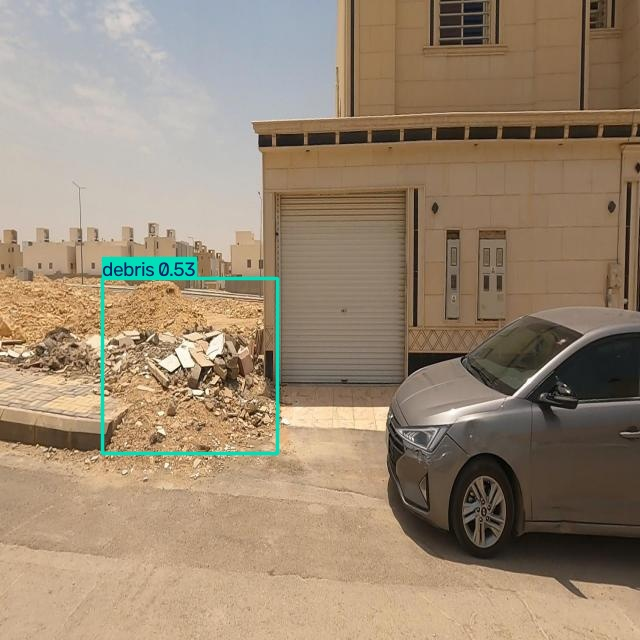

In [10]:
from IPython.display import display, Image
from pathlib import Path

prediction_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\predict"
)

output_images = [
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

if output_images:
    display(Image(filename=str(output_images[0])))
else:
    print("No annotated output image found.")

## 8.2 Extracting Detection Details

YOLO returns the predicted class, confidence score, and bounding-box coordinates for each detected hazard.

The coordinates are represented as `x1`, `y1`, `x2`, and `y2`, corresponding to the top-left and bottom-right corners of the bounding box. These values will be formatted for backend integration.

In [11]:
# Use the results from the previous image-detection cell

result = results[0]
found = []

for box in result.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    found.append({
        "hazard_type": result.names[int(box.cls[0])],
        "confidence": round(float(box.conf[0]), 4),
        "x1": round(x1, 2),
        "y1": round(y1, 2),
        "x2": round(x2, 2),
        "y2": round(y2, 2)
    })

print("Detection results:")
for detection in found:
    print(detection)

print("\nTotal hazards detected:", len(found))

Detection results:
{'hazard_type': 'debris', 'confidence': 0.5257, 'x1': 102.62, 'y1': 278.41, 'x2': 277.38, 'y2': 453.22}

Total hazards detected: 1


## 9. Backend Integration — Hazard Predictor

A reusable prediction function is created to connect the trained YOLO model with the Django backend.

The function accepts an image path or an OpenCV image frame and returns each detected hazard with its class name, confidence score, and bounding-box coordinates.

The output structure is compatible with the backend's `detection_hazard` table.

In [12]:
from ultralytics import YOLO
from pathlib import Path

# Load the best trained model
MODEL_PATH = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard\baseline-2\weights\best.pt"
)

hazard_model = YOLO(str(MODEL_PATH))


def run_detection(source, confidence=0.25):
    """
    Detect road hazards in an image path or OpenCV frame.

    Returns:
        List of dictionaries containing hazard_type, confidence,
        x1, y1, x2, y2.
    """
    results = hazard_model.predict(
        source=source,
        conf=confidence,
        imgsz=416,
        verbose=False
    )

    result = results[0]
    found = []

    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        found.append({
            "hazard_type": result.names[int(box.cls[0])],
            "confidence": float(box.conf[0]),
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2)
        })

    return found


print("✅ Backend-compatible predictor is ready!")

✅ Backend-compatible predictor is ready!


## 9.1 Testing the Backend Predictor

The reusable `run_detection()` function is tested on a sample image from the test dataset. This verifies that the function returns hazard details in the required backend-compatible format.

In [14]:
# Test the predictor on the same test image
detections = run_detection(str(image_path))

print("Detections returned by run_detection():")

for detection in detections:
    print(detection)

print("\nTotal detections:", len(detections))

# Verify the expected output fields
required_fields = {
    "hazard_type", "confidence",
    "x1", "y1", "x2", "y2"
}

if all(required_fields.issubset(d.keys()) for d in detections):
    print("✅ Output format verified!")
else:
    print("⚠️ Check the output fields.")

Detections returned by run_detection():
{'hazard_type': 'debris', 'confidence': 0.5256917476654053, 'x1': 102.62049865722656, 'y1': 278.4062805175781, 'x2': 277.3839111328125, 'y2': 453.223388671875}

Total detections: 1
✅ Output format verified!


## 10. Video-Based Road Hazard Detection

In this step, a road video is processed frame by frame using the trained YOLO model. Each frame is passed to the `run_detection()` function, which returns the detected hazard type, confidence score, and bounding-box coordinates.

The results can later be used to annotate the video and integrate hazard detections with the backend.

In [16]:
from pathlib import Path

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

video_files = [
    p for p in Path(
        r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection"
    ).rglob("*")
    if p.is_file() and p.suffix.lower() in video_extensions
]

print("Video files found:", len(video_files))

for video in video_files[:10]:
    print(video)

Video files found: 0


## 10.1 Video Input

A road video is selected as input for frame-by-frame hazard detection. The video will be processed using OpenCV, and each frame will be passed to the trained YOLO predictor.

In [17]:
from pathlib import Path

video_path = Path(
    r"C:\Users\tript\Downloads\road_video.mp4"
)

if video_path.exists():
    print("✅ Video found:", video_path)
else:
    print("⚠️ Video not found.")
    print("Place your road video in Downloads and update video_path.")

⚠️ Video not found.
Place your road video in Downloads and update video_path.


## 10.2 Selecting the Input Video

A road video is selected from the local computer using a file picker. The selected video will be used for frame-by-frame hazard detection.

In [28]:
from tkinter import Tk, filedialog
from pathlib import Path

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_video = filedialog.askopenfilename(
    title="Select a Road Video",
    filetypes=[
        ("Video files", "*.mp4 *.avi *.mov *.mkv"),
        ("All files", "*.*")
    ]
)

root.destroy()

if selected_video:
    video_path = Path(selected_video)
    print("✅ Video selected:", video_path)
else:
    print("⚠️ No video selected.")

✅ Video selected: C:\Users\tript\Downloads\video_preview_h264 (1).mp4


## 10.3 Frame-by-Frame Video Detection

The selected road video is processed using the trained YOLO model. Each frame is analyzed to identify potholes, cracks, waterlogging, and debris.

The model draws bounding boxes and confidence scores around detected hazards. The processed frames are combined into an annotated output video for visual inspection.

In [29]:
import cv2
from pathlib import Path

# Check the selected video
if not video_path.exists():
    raise FileNotFoundError("Please select a valid road video first.")

# Output folder
output_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_video = output_dir / "road_hazard_detected.mp4"

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise ValueError("Could not open the selected video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0:
    fps = 25.0

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(output_video), fourcc, fps, (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

frame_number = 0
total_detections = 0

try:
    while True:
        success, frame = cap.read()

        if not success:
            break

        frame_number += 1

        # Detect hazards in this frame
        detections = run_detection(frame)
        total_detections += len(detections)

        # Draw boxes and labels
        for d in detections:
            x1, y1 = int(d["x1"]), int(d["y1"])
            x2, y2 = int(d["x2"]), int(d["y2"])

            label = (
                f'{d["hazard_type"]} '
                f'{d["confidence"]:.2f}'
            )

            cv2.rectangle(
                frame, (x1, y1), (x2, y2), (0, 255, 0), 2
            )

            cv2.putText(
                frame,
                label,
                (x1, max(y1 - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

        writer.write(frame)

        if frame_number % 50 == 0:
            print(f"Processed {frame_number}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

print("\n✅ Video detection completed!")
print("Frames processed:", frame_number)
print("Total detections across frames:", total_detections)
print("Output video:", output_video)

Processed 50/692 frames
Processed 100/692 frames
Processed 150/692 frames
Processed 200/692 frames
Processed 250/692 frames
Processed 300/692 frames
Processed 350/692 frames
Processed 400/692 frames
Processed 450/692 frames
Processed 500/692 frames
Processed 550/692 frames
Processed 600/692 frames
Processed 650/692 frames

✅ Video detection completed!
Frames processed: 692
Total detections across frames: 2385
Output video: C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results\road_hazard_detected.mp4


## 10.4 Debugging Video Detection

The video is tested again with a lower confidence threshold to determine whether the model is producing low-confidence predictions. This helps distinguish between a video with no detectable hazards and a model that is struggling to recognize objects in the footage.

In [30]:
import cv2

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise ValueError("Could not open the video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Sample up to 10 frames across the video
sample_count = min(10, total_frames)
frame_indices = [
    int(i * (total_frames - 1) / max(sample_count - 1, 1))
    for i in range(sample_count)
]

low_confidence_results = []

try:
    for frame_idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        success, frame = cap.read()

        if not success:
            continue

        detections = run_detection(frame, confidence=0.10)

        low_confidence_results.append(
            (frame_idx, detections)
        )

finally:
    cap.release()

total_low_conf_detections = sum(
    len(detections)
    for _, detections in low_confidence_results
)

print("Frames sampled:", len(low_confidence_results))
print("Detections at 0.10 confidence:", total_low_conf_detections)

for frame_idx, detections in low_confidence_results:
    if detections:
        print(f"\nFrame {frame_idx}:")
        for detection in detections:
            print(detection)

Frames sampled: 10
Detections at 0.10 confidence: 88

Frame 0:
{'hazard_type': 'waterlogging', 'confidence': 0.365470290184021, 'x1': 195.53509521484375, 'y1': 413.68182373046875, 'x2': 532.8794555664062, 'y2': 540.0}
{'hazard_type': 'waterlogging', 'confidence': 0.27025455236434937, 'x1': 252.4775848388672, 'y1': 207.9099578857422, 'x2': 675.5433349609375, 'y2': 337.97943115234375}
{'hazard_type': 'waterlogging', 'confidence': 0.18941541016101837, 'x1': 149.89598083496094, 'y1': 142.6747589111328, 'x2': 428.9276428222656, 'y2': 242.6194305419922}
{'hazard_type': 'waterlogging', 'confidence': 0.16954870522022247, 'x1': 154.2339630126953, 'y1': 175.63880920410156, 'x2': 285.2635498046875, 'y2': 238.33905029296875}
{'hazard_type': 'waterlogging', 'confidence': 0.1334458738565445, 'x1': 218.16738891601562, 'y1': 177.1770782470703, 'x2': 429.1428527832031, 'y2': 241.13552856445312}
{'hazard_type': 'waterlogging', 'confidence': 0.11926912516355515, 'x1': 263.5255432128906, 'y1': 247.1938781

In [22]:
from pathlib import Path
import random

dataset = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test"
)

# Find a test image whose label contains a pothole (class 0)
pothole_images = []

for label_file in (dataset / "labels").glob("*.txt"):
    lines = label_file.read_text().splitlines()

    if any(line.strip().split()[0] == "0" for line in lines if line.strip()):
        image_path = dataset / "images" / f"{label_file.stem}.jpg"

        if image_path.exists():
            pothole_images.append(image_path)

print("Test images with pothole annotations:", len(pothole_images))

if pothole_images:
    image_path = random.choice(pothole_images)
    print("Selected image:", image_path.name)

    results = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.10,
        save=True,
        project="runs/road_hazard_test",
        name="known_pothole",
        exist_ok=True
    )

    print("Prediction completed.")
else:
    print("No matching JPG image found.")

Test images with pothole annotations: 36
Selected image: road_train_Pothole_4_jpg.rf.d8440fbea792128074e203a85c13257e.jpg

image 1/1 C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test\images\road_train_Pothole_4_jpg.rf.d8440fbea792128074e203a85c13257e.jpg: 640x640 79 potholes, 2 cracks, 296.8ms
Speed: 4.7ms preprocess, 296.8ms inference, 7.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard_test\known_pothole
Prediction completed.


## 8.3 Inspecting Model Predictions

The predicted image is visualized to assess whether the model's bounding boxes align with actual potholes and cracks. This helps identify duplicate detections and false positives before further testing.

Prediction images found: 1


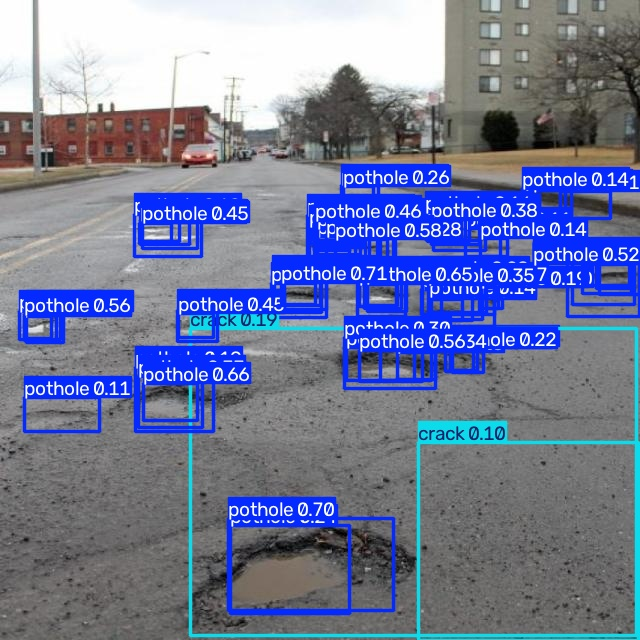

In [23]:
from IPython.display import display, Image
from pathlib import Path

prediction_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard_test\known_pothole"
)

predicted_images = [
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Prediction images found:", len(predicted_images))

if predicted_images:
    display(Image(filename=str(predicted_images[0])))

## 8.4 Reducing Weak Predictions

The trained YOLO model is evaluated using a higher confidence threshold. This filters out low-confidence predictions and helps us inspect whether the remaining detections are more meaningful.

The threshold is adjusted for experimentation and does not guarantee that every remaining prediction is correct.

In [25]:
# Use the same known pothole test image
results_filtered = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.50,
    iou=0.45,
    save=True,
    project="runs/road_hazard_test",
    name="filtered_pothole",
    exist_ok=True
)

result_filtered = results_filtered[0]

print("Detections after filtering:", len(result_filtered.boxes))

for box in result_filtered.boxes:
    print({
        "hazard_type": result_filtered.names[int(box.cls[0])],
        "confidence": round(float(box.conf[0]), 3)
    })


image 1/1 C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test\images\road_train_Pothole_4_jpg.rf.d8440fbea792128074e203a85c13257e.jpg: 640x640 8 potholes, 159.0ms
Speed: 16.9ms preprocess, 159.0ms inference, 3.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard_test\filtered_pothole
Detections after filtering: 8
{'hazard_type': 'pothole', 'confidence': 0.714}
{'hazard_type': 'pothole', 'confidence': 0.704}
{'hazard_type': 'pothole', 'confidence': 0.663}
{'hazard_type': 'pothole', 'confidence': 0.655}
{'hazard_type': 'pothole', 'confidence': 0.579}
{'hazard_type': 'pothole', 'confidence': 0.564}
{'hazard_type': 'pothole', 'confidence': 0.56}
{'hazard_type': 'pothole', 'confidence': 0.521}


## 8.5 Visual Inspection After Confidence Filtering

The prediction generated with a confidence threshold of 0.50 is displayed to assess whether the remaining bounding boxes correspond to actual potholes. This helps evaluate the effect of confidence filtering on prediction quality.

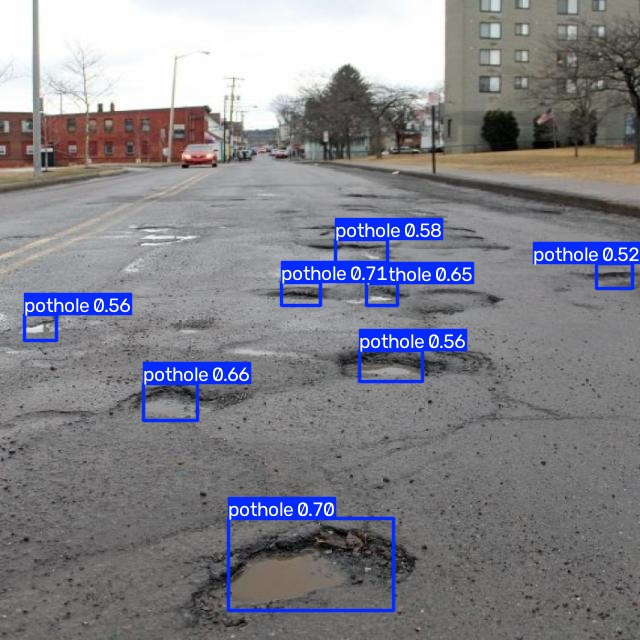

In [26]:
from IPython.display import display, Image
from pathlib import Path

filtered_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\runs\detect\runs\road_hazard_test\filtered_pothole"
)

filtered_images = [
    p for p in filtered_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

if filtered_images:
    display(Image(filename=str(filtered_images[0])))
else:
    print("No filtered prediction image found.")

## 10.5 Video Detection with Confidence Filtering

The trained model is applied to the road video using a confidence threshold of 0.50. This filters out weaker predictions and allows us to inspect whether the model detects visible hazards more reliably in video frames.

In [31]:
import cv2
from pathlib import Path

output_video = (
    Path(r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results")
    / "road_hazard_filtered.mp4"
)
output_video.parent.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise ValueError("Could not open the selected video.")

fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    str(output_video),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the output video.")

frame_count = 0
detection_count = 0

try:
    while True:
        success, frame = cap.read()
        if not success:
            break

        frame_count += 1

        # Use the trained model with a higher confidence threshold
        prediction = hazard_model.predict(
            source=frame,
            imgsz=416,
            conf=0.50,
            verbose=False
        )[0]

        detection_count += len(prediction.boxes)

        annotated_frame = prediction.plot()
        writer.write(annotated_frame)

finally:
    cap.release()
    writer.release()

print("✅ Filtered video processing complete!")
print("Frames processed:", frame_count)
print("Detections across frames:", detection_count)
print("Saved video:", output_video)

✅ Filtered video processing complete!
Frames processed: 692
Detections across frames: 347
Saved video: C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results\road_hazard_filtered.mp4


## Step: Compare Detection Confidence Thresholds

We compare confidence thresholds of 0.35 and 0.50 on the same test video. This helps select a threshold that balances detecting road hazards and reducing false positives.

In [35]:
from pathlib import Path
import cv2

# Replace this with the path of your SECOND input video
video_path = Path(r"C:/Users/tript/Downloads/video_preview_h264.mp4")

print("Video exists:", video_path.exists())

if video_path.exists():
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()

    print("Total frames:", total_frames)
    print("FPS:", fps)
else:
    print("Please enter the correct path to your second video.")

Video exists: True
Total frames: 692
FPS: 25.0


## Confidence Threshold Comparison

Evaluate the trained YOLO model on the same video at confidence thresholds of 0.35 and 0.50. Compare total predictions and the number of frames containing detections.

In [36]:
import cv2
from collections import Counter

def compare_thresholds(video_path, thresholds=(0.35, 0.50), frame_step=10):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError("Could not open the video.")

    total_predictions = Counter()
    frames_with_detections = Counter()
    sampled_frames = 0

    try:
        frame_number = 0

        while True:
            success, frame = cap.read()
            if not success:
                break

            if frame_number % frame_step == 0:
                sampled_frames += 1

                for threshold in thresholds:
                    detections = run_detection(
                        frame,
                        confidence=threshold
                    )

                    total_predictions[threshold] += len(detections)

                    if detections:
                        frames_with_detections[threshold] += 1

            frame_number += 1

    finally:
        cap.release()

    print(f"Frames sampled: {sampled_frames}")
    print()

    for threshold in thresholds:
        print(f"Confidence threshold: {threshold}")
        print("Total predictions:", total_predictions[threshold])
        print("Frames with detections:", frames_with_detections[threshold])
        print()

compare_thresholds(video_path)

Frames sampled: 70

Confidence threshold: 0.35
Total predictions: 123
Frames with detections: 52

Confidence threshold: 0.5
Total predictions: 32
Frames with detections: 19



## Visual Comparison of Confidence Thresholds

Generate two short annotated video clips using confidence thresholds of 0.35 and 0.50. Inspect the same frames to compare genuine hazard detections and false positives.

In [37]:
from pathlib import Path
import cv2

output_dir = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results"
)
output_dir.mkdir(parents=True, exist_ok=True)

def save_comparison_clip(video_path, confidence, duration_seconds=10):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    max_frames = min(
        int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        int(fps * duration_seconds)
    )

    output_path = output_dir / f"comparison_conf_{confidence:.2f}.mp4"
    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    try:
        for _ in range(max_frames):
            success, frame = cap.read()
            if not success:
                break

            results = hazard_model.predict(
                source=frame,
                conf=confidence,
                imgsz=416,
                verbose=False
            )

            annotated = results[0].plot()
            writer.write(annotated)
    finally:
        cap.release()
        writer.release()

    print(f"Saved: {output_path}")

save_comparison_clip(video_path, 0.35)
save_comparison_clip(video_path, 0.50)

Saved: C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results\comparison_conf_0.35.mp4
Saved: C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\video_results\comparison_conf_0.50.mp4


## Verify Backend Handoff ZIP

Check that the ZIP contains the trained model weights, prediction function, and dependency file required for integration with Django.

In [42]:

from pathlib import Path
import zipfile

ZIP_PATH = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\backend_handoff.zip"
)

if not ZIP_PATH.exists():
    print("ERROR: ZIP file not found!")
else:
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        files = z.namelist()

    print("ZIP exists:", ZIP_PATH.exists())
    print("\nFiles inside ZIP:")

    for file in files:
        print("-", file)

    required_files = [
        "weights/best.pt",
        "road_hazard_predictor.py",
        "requirements.txt"
    ]

    print("\nVerification:")
    for file in required_files:
        status = "OK" if file in files else "MISSING"
        print(f"{file}: {status}")


ZIP exists: True

Files inside ZIP:
- weights/
- requirements.txt
- road_hazard_predictor.py
- weights/best.pt

Verification:
weights/best.pt: OK
road_hazard_predictor.py: OK
requirements.txt: OK


## Test the Packaged Road Hazard Predictor

Import the predictor from the generated handoff package and run it on a known road image to verify that the model loads and returns the expected detection fields.

In [43]:

import sys
from pathlib import Path

HANDOFF_DIR = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\backend_handoff"
)

# Make the packaged Python module importable
if str(HANDOFF_DIR) not in sys.path:
    sys.path.insert(0, str(HANDOFF_DIR))

from road_hazard_predictor import run_detection

# Use an image from your dataset that you know exists
TEST_IMAGE = Path(
    r"C:\Users\tript\Downloads\PROJECTS\Road_Hazard_Detection\dataset\road_hazard_final\test\images\road_train_Pothole_4_jpg.rf.d8440fbea792128074e203a85c13257e.jpg"
)

if not TEST_IMAGE.exists():
    print("Test image not found. Please update TEST_IMAGE to an existing image.")
else:
    detections = run_detection(str(TEST_IMAGE), confidence=0.50)

    print("Predictor imported successfully!")
    print("Number of detections:", len(detections))

    for detection in detections:
        print(detection)

    if detections:
        expected_keys = {
            "hazard_type", "confidence",
            "x1", "y1", "x2", "y2"
        }
        print(
            "Output fields valid:",
            all(set(d.keys()) == expected_keys for d in detections)
        )


Predictor imported successfully!
Number of detections: 5
{'hazard_type': 'pothole', 'confidence': 0.7246910929679871, 'x1': 358.3726806640625, 'y1': 343.9413757324219, 'x2': 426.2499084472656, 'y2': 385.6916809082031}
{'hazard_type': 'pothole', 'confidence': 0.6543520092964172, 'x1': 310.7881774902344, 'y1': 219.11866760253906, 'x2': 375.0207214355469, 'y2': 258.7232360839844}
{'hazard_type': 'pothole', 'confidence': 0.5905241966247559, 'x1': 241.27854919433594, 'y1': 542.8187255859375, 'x2': 331.84063720703125, 'y2': 602.6713256835938}
{'hazard_type': 'pothole', 'confidence': 0.5503442287445068, 'x1': 144.4207763671875, 'y1': 381.2379150390625, 'x2': 193.7203369140625, 'y2': 418.3608093261719}
{'hazard_type': 'pothole', 'confidence': 0.5413951277732849, 'x1': 428.13702392578125, 'y1': 283.3734130859375, 'x2': 484.9153137207031, 'y2': 317.5120849609375}
Output fields valid: True
